# Path setup & import packages

In [1]:
%load_ext autoreload
%autoreload 2
import os
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from uws.datasets import create_dataset
from uws.experiments.ptranking_wrapper import PtrankingWrapper
from uws.experiments.real_workflow import get_weak_labels
from uws.ranking import Mallows, Ranking, RankingLabelModel, RankingUtils

root_path = '../../'  # path to the repository root (configs/ and data/ live there)

# Read config & basic setup

In [2]:
config_file_path = '{}/configs/boardgames_ranking_experiment.yaml'.format(root_path)

with open(config_file_path,'r') as conf_file:
    conf = yaml.full_load(conf_file)
    conf['project_root'] = root_path 

data_conf = conf['data_conf']
weak_sup_conf = conf['weak_sup_conf'] # For partial ranking experiments, we should give
l2r_training_conf = conf['l2r_training_conf']
data_conf['project_root'] = root_path

In [3]:
# Reproduce the paper code: its Kendall distance, medoid "Kemeny" rule, Mallows sampler and theta draws
# (weak_sup_conf['legacy']), and its exact item-set sampling (data_conf['legacy_sampling']).
# Set both to False to use the corrected algorithms of uws 1.0.
weak_sup_conf['legacy'] = True
data_conf['legacy_sampling'] = True


# Dataset sampling

In [4]:
dataset= create_dataset(data_conf)
dataset.create_samples()

Generate samples...


# Label model learning & inference

In [5]:
if l2r_training_conf['use_weak_labels']:
    Y_tilde, thetas, individual_kt = get_weak_labels(dataset, weak_sup_conf, root_path=root_path)
    r_utils = RankingUtils(data_conf['dimension'])
    kt = r_utils.mean_kt_distance(Y_tilde,dataset.Y)
    print('Label model kt distance: ', kt)
    dataset.set_Y_tilde(Y_tilde)
else:
    kt = None

/tmp/ipykernel_4002266/3560246651.py:2: UserWarning: No random seed in weak_sup_conf; results are not reproducible
  Y_tilde, thetas, individual_kt = get_weak_labels(dataset, weak_sup_conf, root_path=root_path)


Weak labels generated and saved in ../../data/boardgames/processed/default/LFs/synthetic_weak_labels.pkl
UWS label model: train_method=triplet_opt, inference_rule=weighted_kemeny
Label model kt distance:  0.25206666666666666


# Train and evaluation - mainly with PtrankingWrapper

In [6]:
ptwrapper = PtrankingWrapper(data_conf=data_conf, weak_sup_conf=weak_sup_conf,
                             l2r_training_conf=l2r_training_conf, result_path=conf['results_path'],
                             wl_kt_distance = kt)
X_train, X_test, Y_train, Y_test = dataset.get_train_test_torch(use_weak_labels=l2r_training_conf['use_weak_labels'])
ptwrapper.set_data(X_train=X_train, X_test=X_test,
                  Y_train=Y_train, Y_test=Y_test)
model = ptwrapper.get_model()
result = ptwrapper.train_model(model, verbose=1)

Training data shape, X_train.shape torch.Size([500, 5, 14]) Y_train.shape torch.Size([500, 5])
set_and_load_data in LTREvaluator
(500, 5, 14) (500, 5) (500,)
data_dict {'data_id': 'boardgames', 'dir_data': 'data/boardgames/processed/default', 'min_docs': 10, 'min_rele': 1, 'scale_data': False, 'scaler_id': None, 'scaler_level': None, 'train_presort': True, 'validation_presort': True, 'test_presort': True, 'train_batch_size': 64, 'validation_batch_size': 1, 'test_batch_size': 64, 'unknown_as_zero': False, 'binary_rele': False, 'num_features': 14, 'has_comment': False, 'label_type': <LABEL_TYPE.Permutation: 2>, 'max_rele_level': None, 'fold_num': 1}


data_dict {'data_id': 'boardgames', 'dir_data': 'data/boardgames/processed/default', 'min_docs': 10, 'min_rele': 1, 'scale_data': False, 'scaler_id': None, 'scaler_level': None, 'train_presort': True, 'validation_presort': True, 'test_presort': True, 'train_batch_size': 64, 'validation_batch_size': 1, 'test_batch_size': 64, 'unknown_as_zero': False, 'binary_rele': False, 'num_features': 14, 'has_comment': False, 'label_type': <LABEL_TYPE.Permutation: 2>, 'max_rele_level': None, 'fold_num': 1}


Sequential(
  (FeatureBN): BatchNorm1d(14, eps=1e-05, momentum=1.0, affine=True, bias=True, track_running_stats=False)
  (L_1): Linear(in_features=14, out_features=30, bias=True)
  (BN_1): BatchNorm1d(30, eps=1e-05, momentum=1.0, affine=True, bias=True, track_running_stats=False)
  (ACT_1): ReLU()
  (DR_2): Dropout(p=0.01, inplace=False)
  (L_2): Linear(in_features=30, out_features=30, bias=True)
  (BN_2): BatchNorm1d(30, eps=1e-05, momentum=1.0, affine=True, bias=True, track_running_stats=False)
  (ACT_2): ReLU()
  (L_3): Linear(in_features=30, out_features=1, bias=True)
)


epoch 0, loss [474.8997], train tau 0.32919996976852417, test_tau 0.2321000099182129,train_ndcg@1 tensor([0.6900]), test_ndcg@1 tensor([0.7717])


epoch 1, loss [440.91928], train tau 0.32099997997283936, test_tau 0.2249000370502472,train_ndcg@1 tensor([0.7045]), test_ndcg@1 tensor([0.7740])


...

epoch 3, loss [429.4933], train tau 0.30580002069473267, test_tau 0.22379997372627258,train_ndcg@1 tensor([0.7250]), test_ndcg@1 tensor([0.7795])


epoch 4, loss [426.0329], train tau 0.30059999227523804, test_tau 0.22579997777938843,train_ndcg@1 tensor([0.7300]), test_ndcg@1 tensor([0.7775])


epoch 5, loss [422.90915], train tau 0.296999990940094, test_tau 0.22630000114440918,train_ndcg@1 tensor([0.7360]), test_ndcg@1 tensor([0.7717])


epoch 6, loss [419.6165], train tau 0.2924000024795532, test_tau 0.22519999742507935,train_ndcg@1 tensor([0.7425]), test_ndcg@1 tensor([0.7728])


epoch 7, loss [417.14966], train tau 0.28540000319480896, test_tau 0.2310999631881714,train_ndcg@1 tensor([0.7510]), test_ndcg@1 tensor([0.7660])
result data path ../../tmp/results/boardgames/default generated
The experiment result is saved in ../../tmp/results/boardgames/default/result_summary.pkl


# Training log visualization

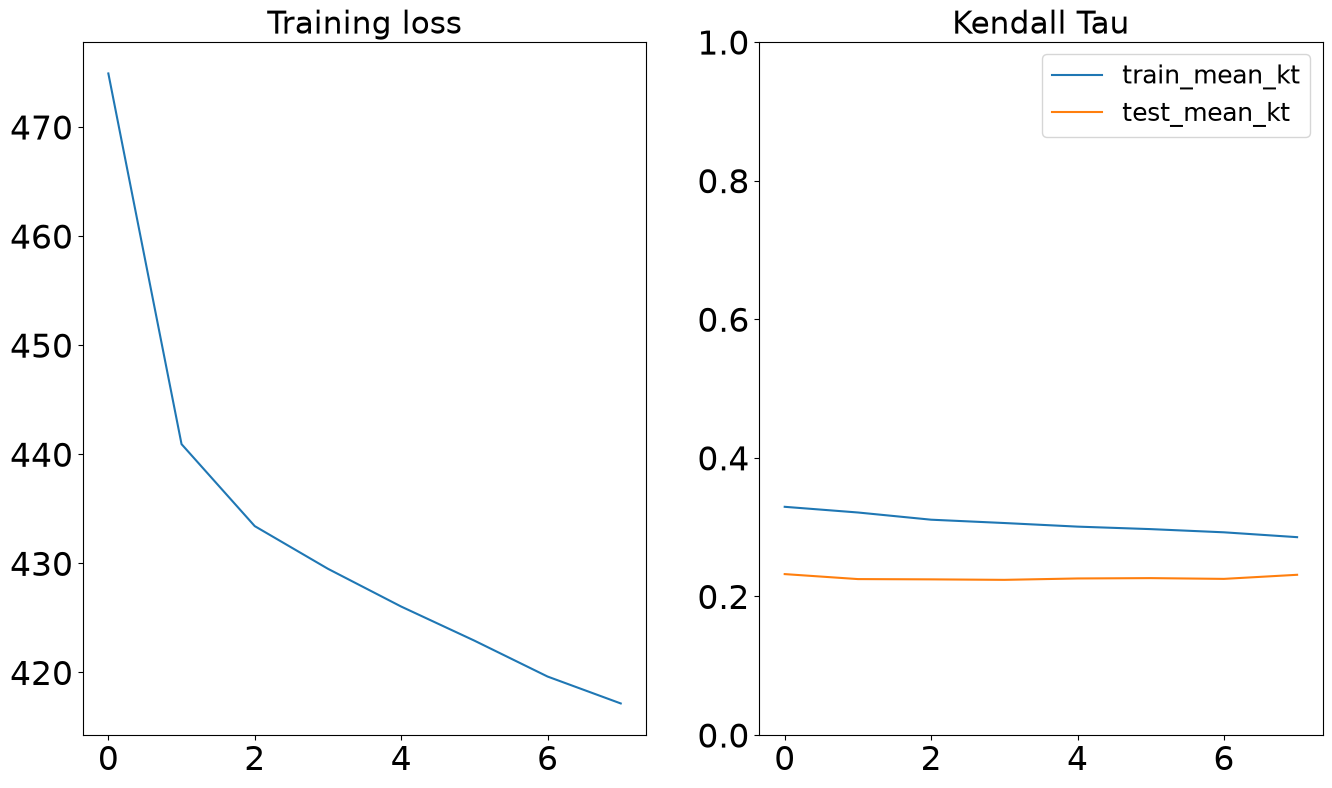

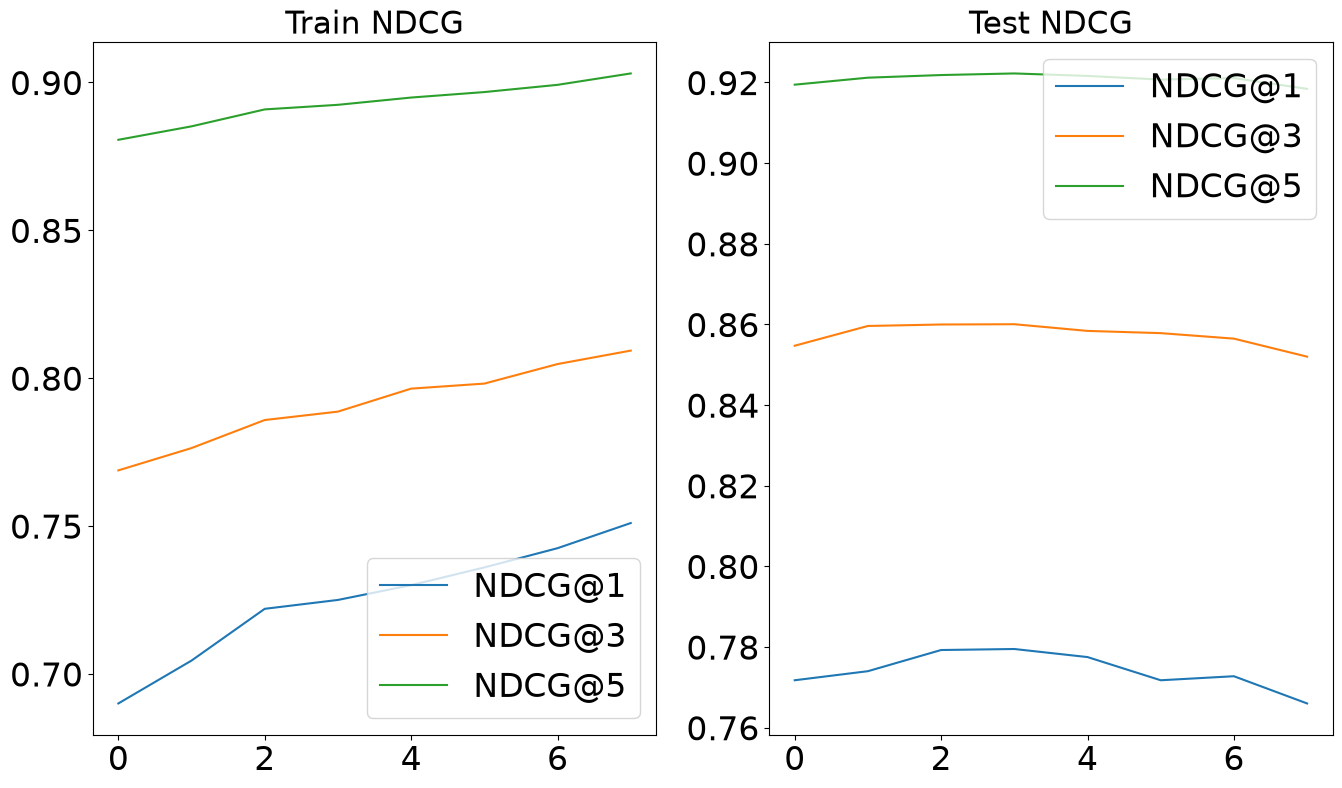

In [7]:
plt.rcParams['font.size'] = '24'
losses = result['loss']
train_tau = result['train_tau']
test_tau = result['test_tau']
train_ndcg1 = result['train_ndcg1']
train_ndcg3 = result['train_ndcg3']
train_ndcg5 = result['train_ndcg5']
test_ndcg1 = result['test_ndcg1']
test_ndcg3 = result['test_ndcg3']
test_ndcg5 = result['test_ndcg5']


fig, axes = plt.subplots(ncols=2, figsize=(16,9))
axes[0].plot(losses)
axes[0].set_title(f'Training loss', fontsize=22)
axes[1].plot(train_tau, label='train_mean_kt')
axes[1].plot(test_tau, label='test_mean_kt')
axes[1].set_ylim(0,1)
axes[1].legend(fontsize=18)
axes[1].set_title(f'Kendall Tau', fontsize=22)
plt.show()

fig, axes = plt.subplots(ncols=2, figsize=(16,9))
axes[0].plot(train_ndcg1, label='NDCG@1')
axes[0].plot(train_ndcg3, label='NDCG@3')
axes[0].plot(train_ndcg5, label='NDCG@5')
axes[0].legend()
axes[0].set_title(f'Train NDCG', fontsize=22)
axes[1].plot(test_ndcg1, label='NDCG@1')
axes[1].plot(test_ndcg3, label='NDCG@3')
axes[1].plot(test_ndcg5, label='NDCG@5')
axes[1].set_title(f'Test NDCG', fontsize=22)
axes[1].legend()
plt.show()